# Visium human glioma IDH-status visualization

This notebook renders per-panel previews plus the main and supplementary PDFs from the workflow caches produced by `workflow.py`. The statistical workflow owns cached tests, permutation nulls, spectra, enrichment, and diagnostics; this notebook owns the plot-specific layout.

In [1]:
# Shared setup: imports, package path, constants, and Matplotlib defaults.
import sys
import warnings
from pathlib import Path
from typing import Any

for cand in (Path.cwd(), *Path.cwd().parents):
    if (cand / "scripts" / "glioma_idh" / "config.py").exists():
        if str(cand) not in sys.path:
            sys.path.insert(0, str(cand))
        __package__ = "scripts.glioma_idh"
        break

import math

import matplotlib as mpl
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from adjustText import adjust_text

from scripts.paper_utils import (
    FIGURE_DPI,
    FIGURE_WIDTH_MM,
    FONT_CONFIG,
    PAPER_CATEGORICAL,
    PAPER_COLORS,
    configure_paper_matplotlib,
    ensure_directories,
    neglog10,
)

from .config import (
    ENRICHMENT_TERMS_FILE,
    FDR_ALPHA,
    FIGURE_DIR,
    FIGURE_GENES,
    GROUP_COLORS,
    GROUP_LABELS,
    GROUP_ORDER,
    MAIN_FIGURE_PDF,
    META_PROGRAM_GENE_MAP_FILE,
    META_PROGRAMS,
    PERMUTATION_NULL_FILE,
    REAL_TESTS_FILE,
    SPATIAL_DIAGNOSTICS_FILE,
    SUPPLEMENTARY_DIAGNOSTICS_PDF,
    SUPPLEMENTARY_METABOLISM_GENES,
)
from .plot_gene_profiles import (
    GliomaGeneProfilePlotter,
    draw_gene_profile_panel,
    load_spectra_cache,
    make_gene_profile_page,
    metadata_from_spectra,
    short_sample_id,
)
from .utils import (
    load_normalized_samples_from_metadata,
    log,
    project_relative,
)

warnings.filterwarnings("ignore", category=UserWarning, message=".*This figure includes Axes.*")

FONT_MIN = FONT_CONFIG["text"]
FONT_TICK = FONT_CONFIG["tick"]
FONT_LABEL = FONT_CONFIG["label"]
FONT_TITLE = FONT_CONFIG["title"]

configure_paper_matplotlib(
    fonts=FONT_CONFIG,
    overrides={
        "pdf.compression": 9,
        "figure.constrained_layout.use": False,
    },
)

ensure_directories(FIGURE_DIR)
print("figure output:", project_relative(MAIN_FIGURE_PDF))

figure output: figures/glioma_idh/idh_main.pdf


## Shared cache and data helpers

In [2]:
def preview_subplot_panel(draw_func, *, figsize=(7.2, 2.1)) -> None:
    """Render one notebook-only preview panel from a subplot-spec helper."""
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(1, 1, figure=fig, left=0.06, right=0.98, top=0.90, bottom=0.14)
    draw_func(gs[0])
    plt.show()
    plt.close(fig)

### Load precomputed workflow results

In [3]:
# Load workflow caches and the normalized samples referenced by the spectra cache.
REAL_TESTS = pd.read_csv(REAL_TESTS_FILE)
META_PROGRAM_GENE_MAP = pd.read_csv(META_PROGRAM_GENE_MAP_FILE)
required_map_columns = {"gene", "rank", "metaprogram"}
if not required_map_columns.issubset(META_PROGRAM_GENE_MAP.columns):
    raise KeyError(
        f"Meta-program map is missing {sorted(required_map_columns - set(META_PROGRAM_GENE_MAP.columns))}"
    )
PERMUTATION_NULL = pd.read_csv(PERMUTATION_NULL_FILE)
DIAGNOSTICS = pd.read_csv(SPATIAL_DIAGNOSTICS_FILE)
SPECTRA_DATA = load_spectra_cache()
SAMPLES, META = load_normalized_samples_from_metadata(metadata_from_spectra(SPECTRA_DATA))

print(f"loaded {REAL_TESTS.shape[0]:,} genes, {len(SPECTRA_DATA['sample_ids'])} samples")

[2026-09-28 00:20:40] loading IDHm_BWH23O
[2026-09-28 00:20:43] loading IDHm_BWH24A
[2026-09-28 00:20:43] loading IDHm_BWH25A
[2026-09-28 00:20:43] loading IDHm_BWH28A
[2026-09-28 00:20:43] loading IDHm_BWH35O
[2026-09-28 00:20:43] loading IDHm_MGH259O
[2026-09-28 00:20:43] loading GBM_MGH258
[2026-09-28 00:20:43] loading GBM_ZH1007inf
[2026-09-28 00:20:43] loading GBM_ZH1007nec
[2026-09-28 00:20:43] loading GBM_ZH1019T1
[2026-09-28 00:20:43] loading GBM_ZH8811Abulk
[2026-09-28 00:20:43] loading GBM_ZH8811Bbulk
[2026-09-28 00:20:43] loading GBM_ZH8812bulk
[2026-09-28 00:20:43] loading GBM_ZH881_inf
[2026-09-28 00:20:43] loading GBM_ZH881T1
[2026-09-28 00:20:44] loading GBM_ZH916bulk
[2026-09-28 00:20:44] loading GBM_ZH916inf
[2026-09-28 00:20:44] loading GBM_ZH916T1
loaded 7,000 genes, 18 samples


### Reusable gene-profile panel plotter


In [4]:
# Per-gene spatial heatmaps and radial profiles are drawn by
# draw_gene_profile_panel() from plot_gene_profiles.py. The same plotter
# is reused by the main and supplementary figures.
PROFILE_PLOTTER = GliomaGeneProfilePlotter(
    tuple(
        dict.fromkeys(
            (
                *FIGURE_GENES,
                *SUPPLEMENTARY_METABOLISM_GENES,
                *(gene for program in META_PROGRAMS for gene in program["genes"]),
            )
        )
    ),
    samples=SAMPLES,
    meta=META,
    spectra_data=SPECTRA_DATA,
    real_tests=REAL_TESTS,
)

## Supplement: sample diagnostics, test overlaps, and permutation null

### Row 1: Per-sample anisotropy, heterogeneity, and patient of origin sanity checks

In [5]:
def _ordered_samples(df: pd.DataFrame) -> list[str]:
    meta = df[["sample_id", "group"]].drop_duplicates().copy()
    group_order = {group: i for i, group in enumerate(GROUP_ORDER)}
    meta["_group_order"] = meta["group"].map(group_order).fillna(99)
    return (
        meta.sort_values(["_group_order", "sample_id"], kind="stable")["sample_id"]
        .astype(str)
        .tolist()
    )


def _plot_anisotropy_boxplots(ax: Any, diagnostics: pd.DataFrame) -> None:
    long = diagnostics.loc[diagnostics["metric"].eq("anisotropy")].copy()
    if long.empty:
        raise ValueError("Spatial diagnostics contain no anisotropy rows.")
    long["anisotropy"] = pd.to_numeric(long["anisotropy"], errors="coerce")
    sample_order = _ordered_samples(long)
    group_by_sample = (
        long[["sample_id", "group"]].drop_duplicates().set_index("sample_id")["group"].to_dict()
    )
    data = [
        long.loc[long["sample_id"].eq(sample), "anisotropy"].dropna().to_numpy(float)
        for sample in sample_order
    ]
    bp = ax.boxplot(
        data,
        positions=np.arange(len(sample_order)),
        widths=0.6,
        patch_artist=True,
        showfliers=False,
        whis=(5, 95),
        manage_ticks=False,
        medianprops={"color": "0.10", "linewidth": 0.5},
        whiskerprops={"color": "0.55", "linewidth": 0.5},
        capprops={"color": "0.55", "linewidth": 0.5},
    )
    for box, sample in zip(bp["boxes"], sample_order, strict=True):
        group = group_by_sample[sample]
        box.set_facecolor(GROUP_COLORS[group])
        box.set_edgecolor("0.25")
        box.set_alpha(0.6)
        box.set_linewidth(0.5)
    ax.set_xticks(np.arange(len(sample_order)))
    ax.set_xticklabels(
        [short_sample_id(s).replace("bulk", "") for s in sample_order],
        rotation=60,
        ha="right",
    )
    ax.set_ylabel("Raw 2D spectral anisotropy", labelpad=1)
    ax.set_title("Gene-wise anisotropy by sample", fontsize=FONT_TITLE, pad=3)
    ax.grid(axis="y", color="0.90", lw=0.5)
    handles = [
        mpl.patches.Patch(
            facecolor=GROUP_COLORS[group],
            edgecolor="0.25",
            alpha=0.6,
            label=f"{GROUP_LABELS[group]} (n={sum(group_by_sample[s] == group for s in sample_order)})",
        )
        for group in GROUP_ORDER
    ]
    ax.legend(handles=handles, frameon=False, loc="upper left", handlelength=1.0)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)


def _sample_palette(sample_ids: list[str]) -> dict[str, Any]:
    return {
        sample: PAPER_CATEGORICAL[i % len(PAPER_CATEGORICAL)] for i, sample in enumerate(sample_ids)
    }


def _idh_wt_donor_id(sample_id: str) -> str:
    """Return the Greenwald tumor ID shared by sampled GBM regions."""
    core = sample_id.removeprefix("GBM_")
    # These patients with multiple samples are all IDH-wildtype
    for donor in ("MGH258", "ZH1007", "ZH1019", "ZH881", "ZH916"):
        if core.startswith(donor):
            return donor
    raise ValueError(f"Unknown IDH-wildtype donor for sample {sample_id!r}")


def _spectral_variability_by_donor(spectra_data: dict[str, Any]) -> dict[str, dict[str, Any]]:
    """Summarize per-gene spectral distance within and between IDH-wt donors."""
    # Load precomputed spectra and sample metadata for each sample
    spectra = np.asarray(spectra_data["spectra"], dtype=float)
    sample_ids = np.asarray(spectra_data["sample_ids"], dtype=str)
    groups = np.asarray(spectra_data["groups"], dtype=str)

    # Subset to IDH-wildtype samples and map each sample to its donor ID
    wt_indices = np.flatnonzero(groups == GROUP_ORDER[1])
    donors = {i: _idh_wt_donor_id(sample_ids[i]) for i in wt_indices}
    eps = 1e-12
    transforms = {
        "Raw spectra": spectra,
        "L1-normalized": spectra / np.maximum(spectra.sum(axis=2, keepdims=True), eps),
    }
    out: dict[str, dict[str, Any]] = {}
    for label, values in transforms.items():
        pair_distances = {"within": [], "between": []}
        # Compute pairwise distances between all IDH-wt samples, grouped by donor
        for pos, i in enumerate(wt_indices):
            for j in wt_indices[pos + 1 :]:
                relation = "within" if donors[i] == donors[j] else "between"
                distance = np.abs(values[i] - values[j]) / (0.5 * (values[i] + values[j]) + eps)
                pair_distances[relation].append(np.nanmean(distance, axis=1))
        out[label] = {
            relation: np.nanmean(np.stack(distances), axis=0)
            for relation, distances in pair_distances.items()
        }
        out[label]["pair_counts"] = {
            relation: len(distances) for relation, distances in pair_distances.items()
        }
    return out


def _plot_donor_spectral_variability(ax: Any, spectra_data: dict[str, Any]) -> None:
    """Plot within- versus between-donor spectral variability for IDH-wt regions."""
    variability = _spectral_variability_by_donor(spectra_data)
    relations = ("within", "between")
    colors = {"within": PAPER_COLORS["neutral"], "between": PAPER_COLORS["ochre"]}
    offsets = {"within": -0.17, "between": 0.17}
    modes = tuple(variability)
    n_genes = len(variability[modes[0]]["within"])
    for relation in relations:
        bp = ax.boxplot(
            [variability[mode][relation] for mode in modes],
            positions=np.arange(len(modes)) + offsets[relation],
            widths=0.25,
            patch_artist=True,
            showfliers=False,
            whis=(5, 95),
            manage_ticks=False,
            medianprops={"color": "0.10", "linewidth": 0.5},
            whiskerprops={"color": "0.55", "linewidth": 0.5},
            capprops={"color": "0.55", "linewidth": 0.5},
        )
        for box in bp["boxes"]:
            box.set_facecolor(colors[relation])
            box.set_edgecolor("0.25")
            box.set_alpha(0.6)
            box.set_linewidth(0.5)
    pair_counts = variability[modes[0]]["pair_counts"]
    relation_labels = {"within": "Within individual", "between": "Between individuals"}
    handles = [
        mpl.patches.Patch(
            facecolor=colors[relation],
            edgecolor="0.25",
            alpha=0.68,
            label=f"{relation_labels[relation]} (n={pair_counts[relation]} pairs)",
        )
        for relation in relations
    ]
    ax.set_xticks(np.arange(len(modes)), modes)
    ax.set_xlabel(f"Spectrum type (n={n_genes:,} genes/box)", labelpad=1)
    ax.set_ylabel("Per-gene mean relative spectral distance", labelpad=1)
    ax.set_ylim(bottom=0)
    ax.set_title("IDH-wt spectral variability", fontsize=FONT_TITLE, pad=3)
    ax.grid(axis="y", color="0.90", lw=0.5)
    ax.legend(handles=handles, frameon=False, loc="upper right", handlelength=1.0)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)


def _plot_effective_rank_scatter(ax: Any, diagnostics: pd.DataFrame) -> None:
    # Extract effective-rank rows and pivot to wide format for plotting
    ranks = diagnostics.loc[diagnostics["metric"].eq("effective_rank")].copy()
    wide = ranks.pivot_table(
        index=["sample_id", "group"],
        columns="basis",
        values="effective_rank",
        aggfunc="first",
    ).reset_index()
    wide = wide.dropna(subset=["expression_spots", "radial_power_bins"])
    sample_order = _ordered_samples(wide)
    colors = _sample_palette(sample_order)
    texts, text_x, text_y = [], [], []
    for row in wide.itertuples(index=False):
        sample = str(row.sample_id)
        ax.scatter(
            row.expression_spots,
            row.radial_power_bins,
            s=15,
            color=colors[sample],
            # edgecolor="0.20",
            # linewidth=0.5,
            zorder=3,
        )
        texts.append(
            ax.text(
                row.expression_spots,
                row.radial_power_bins,
                short_sample_id(sample).replace("bulk", ""),
                fontsize=FONT_MIN,
                ha="left",
                va="bottom",
                color="0.20",
                # bbox={"fc": "white", "ec": "none", "alpha": 0.65, "pad": 0.05},
                zorder=4,
            )
        )
        text_x.append(float(row.expression_spots))
        text_y.append(float(row.radial_power_bins))
    ax.margins(x=0.12, y=0.12)
    adjust_text(
        texts,
        x=text_x,
        y=text_y,
        ax=ax,
        expand=(1.05, 1.12),
        force_text=(0.5, 0.5),
        force_static=(0.5, 0.5),
        max_move=(24, 24),
        iter_lim=1000,
        arrowprops={"arrowstyle": "-", "lw": 0.5, "color": "0.55"},
    )
    ax.set_xlabel("Effective number of spots", labelpad=1)
    ax.set_ylabel("Effective number of radial spectral bins", labelpad=1)
    ax.set_title(
        "Cross-gene heterogeneity by covariance effective rank", fontsize=FONT_TITLE, pad=3
    )
    ax.grid(color="0.9", lw=0.5)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)


def plot_sample_diagnostics_row(spec) -> None:
    """Draw anisotropy, effective-rank, and donor-dependence diagnostics."""
    gs = gridspec.GridSpecFromSubplotSpec(
        1,
        3,
        subplot_spec=spec,
        width_ratios=[1.32, 1.28, 1.20],
        wspace=0.30,
    )
    ax = plt.gcf().add_subplot(gs[0, 0])
    _plot_anisotropy_boxplots(ax, DIAGNOSTICS)
    ax = plt.gcf().add_subplot(gs[0, 1])
    _plot_effective_rank_scatter(ax, DIAGNOSTICS)
    ax = plt.gcf().add_subplot(gs[0, 2])
    _plot_donor_spectral_variability(ax, SPECTRA_DATA)

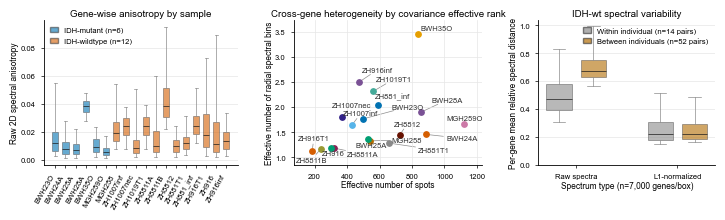

In [6]:
# Preview the sample-level diagnostic row without writing a PDF.
preview_subplot_panel(plot_sample_diagnostics_row, figsize=(7.3, 1.9))

### Row 2: Null-calibration and test agreements

In [7]:
def _ecdf_values(values: Any) -> tuple[np.ndarray, np.ndarray]:
    """Return empirical-CDF coordinates for finite values."""
    x = np.sort(np.asarray(values, dtype=float))
    x = x[np.isfinite(x)]
    return x, np.arange(1, x.size + 1, dtype=float) / max(x.size, 1)


def _plot_permutation_null_ecdf(ax: Any, test: str) -> None:
    """Plot pooled null p-values across deterministic label shuffles."""
    sub = PERMUTATION_NULL.loc[PERMUTATION_NULL["test"].eq(test)].copy()
    if sub.empty:
        raise ValueError(f"Permutation cache contains no {test} rows.")
    x, y = _ecdf_values(sub["P_value"])
    n_shuffles = sub["perm_idx"].nunique()
    color = {"DF": PAPER_COLORS["cool"], "DF_norm": PAPER_COLORS["warm"]}[test]
    label = (
        f"Pooled $P$ from {n_shuffles} shuffles;\n"
        f"False positive rate @ 0.05: "
        f"{sub['P_value'].lt(0.05).mean():.3f}"
    )
    ax.plot(x, y, color=color, lw=1.1, label=label)
    ax.plot([0, 1], [0, 1], color="0.60", lw=0.55, ls="--", zorder=0)
    ax.axvline(0.05, color="0.75", lw=0.5, ls=":", zorder=0)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("$P$ under permuted labels", labelpad=1)
    ax.set_ylabel("Empirical CDF", labelpad=1)
    display = "DF-norm" if test == "DF_norm" else test
    ax.set_title(f"Null calibration: {display}", fontsize=FONT_TITLE, pad=3)
    ax.legend(frameon=False, loc="lower right", handlelength=1.2, borderaxespad=0.2)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)


def _overlap_rows(
    real_tests: pd.DataFrame,
) -> tuple[list[dict[str, Any]], dict[str, int]]:
    tests = (
        ("DE", "P_adj_DE"),
        ("DF", "P_adj_DF"),
        ("DF-norm", "P_adj_DF_norm"),
    )
    sig = {name: real_tests[col].to_numpy(float) <= FDR_ALPHA for name, col in tests}
    set_sizes = {name: int(mask.sum()) for name, mask in sig.items()}
    combos = (
        ("DE",),
        ("DF",),
        ("DF-norm",),
        ("DE", "DF"),
        ("DE", "DF-norm"),
        ("DF", "DF-norm"),
        ("DE", "DF", "DF-norm"),
    )
    rows: list[dict[str, Any]] = []
    for combo in combos:
        mask = np.ones(real_tests.shape[0], dtype=bool)
        members = set(combo)
        for name, _col in tests:
            mask &= sig[name] if name in members else ~sig[name]
        rows.append({"combo": combo, "count": int(mask.sum())})
    return rows, set_sizes


def _plot_overlap_panel(fig: Any, spec: Any, real_tests: pd.DataFrame) -> None:
    rows, set_sizes = _overlap_rows(real_tests)
    gs = gridspec.GridSpecFromSubplotSpec(
        2,
        1,
        subplot_spec=spec,
        height_ratios=[2.8, 1.35],
        hspace=0.03,
    )
    ax_bar = fig.add_subplot(gs[0])
    ax_mat = fig.add_subplot(gs[1], sharex=ax_bar)

    x = np.arange(len(rows))
    counts = np.asarray([row["count"] for row in rows], dtype=int)
    ax_bar.bar(x, counts, width=0.68, color="0.45")
    for xi, value in zip(x, counts, strict=True):
        ax_bar.text(
            xi,
            value + max(counts.max(), 1) * 0.035,
            str(value),
            ha="center",
            va="bottom",
            fontsize=FONT_TICK,
        )
    ax_bar.set_ylim(0, max(counts.max(), 1) * 1.22)
    ax_bar.set_ylabel("Exact overlap", labelpad=1)
    ax_bar.set_title(f"Test hits intersections (FDR $\\leq$ {FDR_ALPHA})", fontsize=FONT_TITLE, pad=3)
    ax_bar.set_xticks([])
    for spine in ("top", "right"):
        ax_bar.spines[spine].set_visible(False)

    test_rows = ("DE", "DF", "DF-norm")
    colors = {
        "DE": PAPER_COLORS["neutral"],
        "DF": PAPER_COLORS["cool"],
        "DF-norm": PAPER_COLORS["warm"],
    }
    y_positions = np.arange(len(test_rows))[::-1]
    for xi, row in zip(x, rows, strict=True):
        included = set(row["combo"])
        ax_mat.scatter(
            [xi] * len(test_rows),
            y_positions,
            s=13,
            color="0.86",
            linewidths=0,
            zorder=1,
        )
        active_y = [y for y, name in zip(y_positions, test_rows, strict=True) if name in included]
        if len(active_y) > 1:
            ax_mat.plot([xi, xi], [min(active_y), max(active_y)], color="0.25", lw=0.8, zorder=2)
        for y, name in zip(y_positions, test_rows, strict=True):
            if name in included:
                ax_mat.scatter([xi], [y], s=18, color=colors[name], linewidths=0, zorder=3)

    ax_mat.set_yticks(y_positions)
    row_labels = {
        "DE": f"DE {set_sizes['DE']}",
        "DF": f"DF {set_sizes['DF']}",
        "DF-norm": f"DF-norm {set_sizes['DF-norm']}",
    }
    ax_mat.set_yticklabels([row_labels[name] for name in test_rows])
    ax_mat.set_ylim(-0.6, len(test_rows) - 0.4)
    ax_mat.set_xlim(-0.55, len(rows) - 0.45)
    ax_mat.set_xticks([])
    ax_mat.tick_params(axis="y", length=0, pad=1)
    for spine in ("top", "right", "bottom"):
        ax_mat.spines[spine].set_visible(False)


def plot_overlap_and_permutation_row(spec) -> None:
    """Draw empirical null CDFs and the significant-set overlap."""
    gs = gridspec.GridSpecFromSubplotSpec(
        1, 3, subplot_spec=spec, width_ratios=[1.0, 1.0, 1.15], wspace=0.32
    )
    for col, test in enumerate(("DF", "DF_norm")):
        _plot_permutation_null_ecdf(plt.gcf().add_subplot(gs[0, col]), test)
    _plot_overlap_panel(plt.gcf(), gs[0, 2], REAL_TESTS)

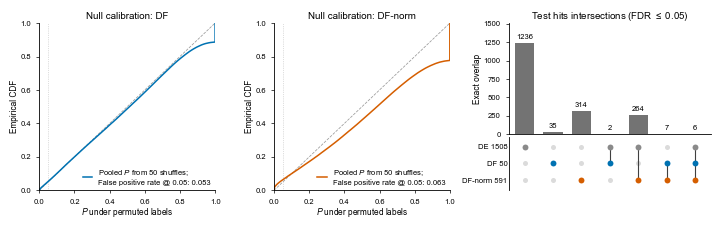

In [8]:
# Preview the null-calibration and overlap row without writing a PDF.
preview_subplot_panel(plot_overlap_and_permutation_row, figsize=(7.3, 2.2))

### Row 3: IDH-linked metabolism positive controls

In [9]:
def plot_metabolism_positive_control_profiles(spec) -> None:
    """Draw canonical controls for IDH-linked metabolism."""
    labels = {
        "BCAT1": "canonical IDH-linked amino acid metabolism",
        "LDHA": "IDH-linked hypermethylation / glycolytic silencing",
    }
    gs = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=spec, wspace=0.22)
    for col, gene in enumerate(SUPPLEMENTARY_METABOLISM_GENES):
        draw_gene_profile_panel(
            plt.gcf(),
            gs[0, col],
            plotter=PROFILE_PLOTTER,
            gene=gene,
            narrative_label=labels[gene],
            show_legend=True,
        )

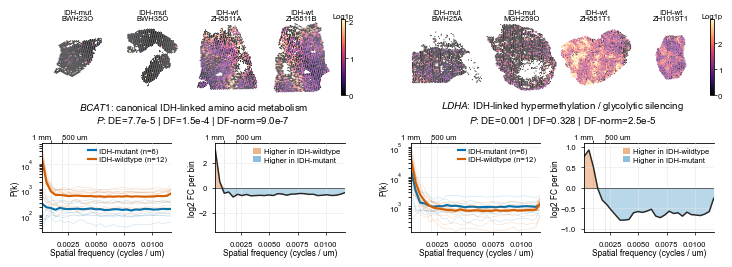

In [10]:
# Preview supplementary metabolism controls without writing a PDF.
preview_subplot_panel(plot_metabolism_positive_control_profiles, figsize=(7.3, 2.8))

### Save as a combined figure

In [11]:
def build_idh_status_supplement() -> plt.Figure:
    """Assemble diagnostics, negative controls, and metabolism controls."""
    fig = plt.figure(figsize=(FIGURE_WIDTH_MM / 25.4, 190 / 25.4))
    outer = gridspec.GridSpec(
        3,
        1,
        figure=fig,
        left=0.05,
        right=0.97,
        top=0.95,
        bottom=0.05,
        height_ratios=[0.85, 0.8, 1.6],
        hspace=0.4,
    )
    plot_sample_diagnostics_row(outer[0])
    plot_overlap_and_permutation_row(outer[1])
    plot_metabolism_positive_control_profiles(outer[2])
    return fig

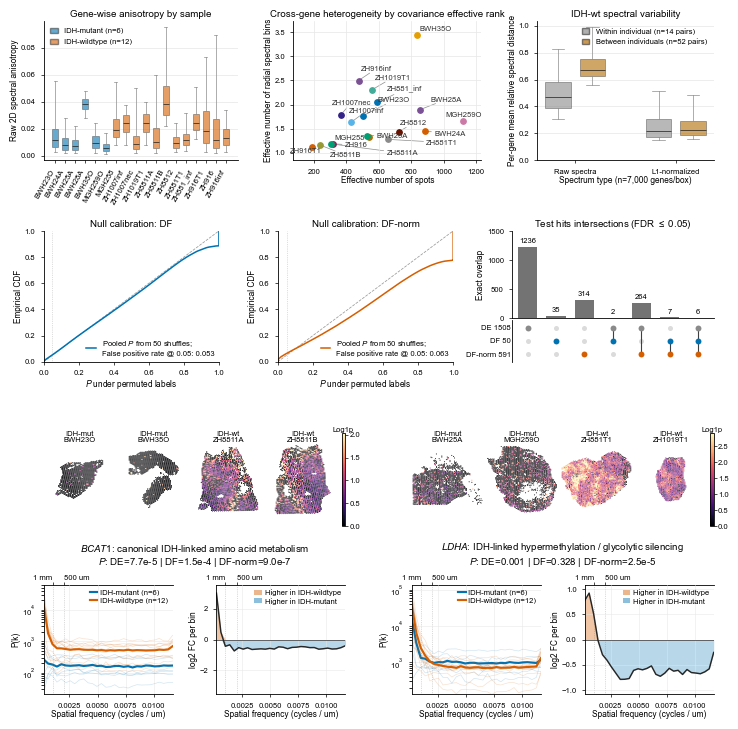

In [12]:
# Preview the combined supplementary diagnostics figure.
fig = build_idh_status_supplement()
plt.show()
plt.close(fig)

In [13]:
# Save the combined supplementary diagnostics figure to PDF.
fig = build_idh_status_supplement()
fig.savefig(SUPPLEMENTARY_DIAGNOSTICS_PDF, bbox_inches=None, dpi=FIGURE_DPI)
plt.close(fig)
log(f"wrote {project_relative(SUPPLEMENTARY_DIAGNOSTICS_PDF)}")

[2026-09-28 00:20:48] wrote figures/glioma_idh/idh_supp.pdf


## Main figure: IDH-status spatial pattern analysis

### Load and check pathway enrichment results

In [14]:
def _parse_gene_list(value: Any) -> list[str]:
    """Parse clusterProfiler's slash-delimited hit-gene field."""
    if pd.isna(value):
        return []
    return list(dict.fromkeys(gene for gene in str(value).split("/") if gene))


def load_enrichment_terms(path: Path = ENRICHMENT_TERMS_FILE) -> pd.DataFrame:
    """Load the current clusterProfiler GO/KEGG cache schema."""
    terms = pd.read_csv(path)
    required = {
        "gene_set",
        "source",
        "native",
        "name",
        "description",
        "p_value",
        "p_adjust",
        "intersection_size",
        "hit_genes",
        "semantic_simplified",
    }
    missing = required - set(terms.columns)
    if missing:
        raise ValueError(f"Enrichment cache uses an obsolete schema; missing: {sorted(missing)}")
    terms = terms[terms["gene_set"].isin(["DE", "DF_norm"])].copy()
    if terms.empty:
        raise ValueError("Enrichment cache contains no DE or DF-norm rows.")
    terms["p_value"] = pd.to_numeric(terms["p_value"], errors="coerce")
    terms = terms.dropna(subset=["p_value"])
    terms["p_adjust"] = pd.to_numeric(terms["p_adjust"], errors="coerce").fillna(1.0)
    terms["intersection_size"] = pd.to_numeric(terms["intersection_size"], errors="raise")
    terms["hit_gene_list"] = terms["hit_genes"].map(_parse_gene_list)
    terms["enrichment_score"] = neglog10(terms["p_adjust"])
    covid_text = terms[["name", "native", "description"]].fillna("").agg(" ".join, axis=1)
    terms = terms.loc[~covid_text.str.contains("covid|sars|coronavirus", case=False, regex=True)]
    return terms.sort_values(["gene_set", "p_value"], kind="stable")


ENRICHMENT = load_enrichment_terms()
print(f"enrichment terms: {ENRICHMENT.shape[0]:,}")

enrichment terms: 4,104


In [15]:
plot_df = ENRICHMENT.query(
    'q_value < 0.05 and gene_set == "DF_norm" and semantic_simplified != False'
).copy()
plot_df.sort_values("q_value").head(10).filter(
    [
        "gene_set",
        "source",
        "native",
        "name",
        "description",
        "q_value",
        "intersection_size",
        "semantic_simplified",
        "hit_gene_list",
    ]
)

,gene_set,source,native,name,description,q_value,intersection_size,semantic_simplified,hit_gene_list
1842,DF_norm,KEGG,hsa04820,Cytoskeleton in muscle cells,Cytoskeleton in muscle cells,0.000010,13,NaN,"[FN1, COL3A1, COL1A1, COL6A1, VIM, COL1A2, ENO..."
1843,DF_norm,KEGG,hsa04512,ECM-receptor interaction,ECM-receptor interaction,0.000034,8,NaN,"[FN1, COL1A1, COL6A1, COL1A2, AGRN, COL6A2, CO..."
1844,DF_norm,KEGG,hsa04974,Protein digestion and absorption,Protein digestion and absorption,0.000034,7,NaN,"[COL3A1, COL1A1, COL6A1, COL1A2, COL18A1, COL6..."
1845,DF_norm,KEGG,hsa04518,Integrin signaling,Integrin signaling,0.000079,10,NaN,"[FN1, C3, COL1A1, VEGFA, COL6A1, COL1A2, ACTG1..."
1846,DF_norm,GO:BP,GO:0006959,humoral immune response,humoral immune response,0.000306,9,True,"[LGALS3, GAPDH, SLPI, C3, A2M, CCL2, C1QA, C1Q..."
1847,DF_norm,GO:BP,GO:0009612,response to mechanical stimulus,response to mechanical stimulus,0.001339,10,True,"[PTN, IGFBP2, COL1A1, COL6A1, RCAN1, MAP1B, SL..."
1848,DF_norm,GO:BP,GO:0006956,complement activation,complement activation,0.001339,5,True,"[C3, A2M, C1QA, C1QB, C1QC]"
1854,DF_norm,GO:BP,GO:0001568,blood vessel development,blood vessel development,0.002247,17,True,"[FN1, COL3A1, C3, COL1A1, VEGFA, COL1A2, TGFBI..."
1849,DF_norm,KEGG,hsa05322,Systemic lupus erythematosus,Systemic lupus erythematosus,0.002255,5,NaN,"[C3, C1QA, C1QB, HLA-DPA1, C1QC]"
1850,DF_norm,KEGG,hsa04510,Focal adhesion,Focal adhesion,0.002255,10,NaN,"[FN1, COL1A1, VEGFA, COL6A1, COL1A2, ACTG1, EM..."


### Row 1: DE versus DF-norm and pathway enrichment contrast

In [16]:
def _plot_de_df_norm_scatter(
    ax: Any,
    real_tests: pd.DataFrame,
    meta_programs: tuple[dict[str, Any], ...],
    gene_map: pd.DataFrame,
) -> None:
    """Contrast gene-level tests using cached meta-program assignments."""
    x = neglog10(real_tests["P_DE"])
    y = neglog10(real_tests["P_DF_norm"])
    features = real_tests["Feature"].astype(str)
    top_genes = set(gene_map["gene"].astype(str))
    top_mask = features.isin(top_genes).to_numpy()
    ax.scatter(
        x[~top_mask],
        y[~top_mask],
        s=3,
        color="0.82",
        alpha=0.38,
        linewidths=0,
        rasterized=True,
    )

    assignments = gene_map.set_index("gene")["metaprogram"].astype(str)
    unassigned = features.map(assignments).fillna("not_top100").eq("unassigned").to_numpy()
    ax.scatter(
        x[unassigned],
        y[unassigned],
        s=6,
        color="#A6A6A6",
        alpha=0.80,
        linewidths=0,
        label="Unassigned",
        zorder=3,
    )
    by_gene = real_tests.set_index("Feature")
    for program in meta_programs:
        genes = gene_map.loc[gene_map["metaprogram"].eq(program["key"]), "gene"].astype(str)
        rows = by_gene.loc[genes]
        ax.scatter(
            neglog10(rows["P_DE"]),
            neglog10(rows["P_DF_norm"]),
            s=6,
            color=program["color"],
            alpha=0.82,
            linewidths=0,
            label=program["label"],
            zorder=3,
        )
    x_max = max(float(np.nanmax(x)), 1.0)
    y_max = max(float(np.nanmax(y)), 1.0)
    ax.set_xlim(0, x_max * 1.06)
    ax.set_ylim(0, y_max * 1.08)
    identity_max = min(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([0, identity_max], [0, identity_max], color="0.70", lw=0.65, ls=":")
    # Keep automatic face colors; use configured colors for outlines and labels.
    texts, text_x, text_y = [], [], []
    for program in meta_programs:
        genes = list(program["genes"])
        manual_color = program["color"]
        rows = by_gene.loc[genes]
        gx = neglog10(rows["P_DE"])
        gy = neglog10(rows["P_DF_norm"])
        for gene, gene_x, gene_y in zip(genes, gx, gy, strict=True):
            ax.scatter(
                [gene_x],
                [gene_y],
                s=17,
                facecolor="none",
                edgecolor=manual_color,
                linewidth=0.75,
                zorder=5,
            )
            texts.append(
                ax.text(
                    gene_x,
                    gene_y,
                    gene,
                    fontsize=FONT_MIN,
                    fontstyle="italic",
                    color=PAPER_COLORS["charcoal"],
                    ha="left",
                    va="bottom",
                    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.72, "pad": 0.12},
                    zorder=6,
                )
            )
            text_x.append(gene_x)
            text_y.append(gene_y)
    adjust_text(
        texts,
        x=text_x,
        y=text_y,
        ax=ax,
        expand=(1.1, 1.2),
        force_text=(1.3, 1.3),
        force_static=(1.3, 1.3),
        force_pull=(0.01, 0.02),
        max_move=(30, 30),
        iter_lim=1000,
        arrowprops={"arrowstyle": "-", "lw": 0.5, "color": "0.45"},
    )
    ax.set_xlabel("-log10 $P$ (DE)", labelpad=1)
    ax.set_ylabel("-log10 $P$ (DF-norm)", labelpad=1)
    ax.set_title("DE vs DF-norm (IDH status glioma)", fontsize=FONT_TITLE, pad=3)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)


def _short_term_name(name: str, *, max_chars: int = 58) -> str:
    text = str(name).replace("_", " ")
    if len(text) <= max_chars:
        return text
    return text[: max_chars - 1].rstrip() + "..."


def _display_term_name(source: str, native: str, name: str) -> str:
    """Use sentence case for KEGG terms while preserving acronyms."""
    text = "regulation of VEGF signaling pathway" if native == "GO:1900746" else str(name)
    leading = text.split(maxsplit=1)[0].split("-", maxsplit=1)[0]
    if source == "KEGG" and not (len(leading) >= 2 and leading.isupper()):
        text = text[:1].lower() + text[1:]
    return text


def _meta_program_enrichment(
    enrichment: pd.DataFrame, meta_programs: tuple[dict[str, Any], ...]
) -> pd.DataFrame:
    """Pair DE and DF-norm intersections for curated GO and KEGG terms."""
    rows = []
    for program_order, program in enumerate(meta_programs):
        for source, native, term_name in program["terms"]:
            sub = enrichment.loc[enrichment["source"].eq(source) & enrichment["native"].eq(native)]
            norm = sub.loc[sub["gene_set"].eq("DF_norm")]
            if norm.empty:
                raise KeyError(f"Missing DF-norm enrichment term: {term_name}")
            norm_row = norm.iloc[0]
            retained = source != "GO:BP" or (
                pd.notna(norm_row.get("semantic_simplified"))
                and bool(norm_row.get("semantic_simplified"))
            )
            if float(norm_row["p_adjust"]) > FDR_ALPHA or not retained:
                raise ValueError(f"Selected term is not significant and simplified: {term_name}")
            de = sub.loc[sub["gene_set"].eq("DE")]
            de_fdr = float(de.iloc[0]["p_adjust"]) if not de.empty else 1.0
            norm_fdr = float(norm_row["p_adjust"])
            if norm_fdr >= de_fdr:
                raise ValueError(f"Selected term is not DF-norm preferred: {term_name}")
            rows.append(
                {
                    "program_order": program_order,
                    "program": program["label"],
                    "program_short": program["short_label"],
                    "color": program["color"],
                    "name": _display_term_name(source, native, norm_row["name"]),
                    "DF_norm_p_adjust": norm_fdr,
                    "DF_norm_score": float(norm_row["enrichment_score"]),
                    "DE_intersection_size": int(de.iloc[0]["intersection_size"])
                    if not de.empty
                    else 0,
                    "DF_norm_intersection_size": int(norm_row["intersection_size"]),
                }
            )
    return pd.DataFrame(rows).sort_values(["program_order", "DF_norm_p_adjust"], kind="stable")


def _plot_enrichment_panel(ax: Any, enrichment: pd.DataFrame) -> None:
    plot_df = _meta_program_enrichment(enrichment, META_PROGRAMS)

    y = np.arange(plot_df.shape[0], dtype=float)
    norm_score = plot_df["DF_norm_score"].to_numpy(float)
    score_max = max(1.0, float(norm_score.max()))
    label_gap = max(6.0, score_max * 1.25)
    ax.barh(y, norm_score, height=0.70, color=plot_df["color"], alpha=0.88)
    ax.axvline(0, color="0.25", lw=0.55)
    ax.set_xlim(-label_gap, score_max * 1.42)
    ax.set_yticks([])
    for yi, row in zip(y, plot_df.itertuples(index=False), strict=True):
        ax.text(
            -0.15,
            yi,
            f"{row.program_short}: {_short_term_name(row.name, max_chars=39)}",
            ha="right",
            va="center",
            fontsize=FONT_MIN,
            color=row.color,
        )
        ax.text(
            row.DF_norm_score + score_max * 0.025,
            yi,
            f"{row.DE_intersection_size:d} | {row.DF_norm_intersection_size:d}",
            ha="left",
            va="center",
            fontsize=FONT_MIN,
            color="0.20",
        )
    ax.set_xticks(np.arange(0, math.ceil(score_max) + 1, 2))
    ax.set_xlabel(r"$-\log_{10}(\mathrm{FDR})$ (from DF-norm top 100 genes)", labelpad=1)
    ax.set_title("Top DF-norm-preferred GO and KEGG terms", fontsize=FONT_TITLE, pad=3)
    ax.text(
        1.0,
        0.985,
        "Top 100 gene intersections\nDE | DF-norm",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=FONT_MIN,
        color="0.30",
    )
    ax.set_ylim(-1.25, y[-1] + 0.7)
    ax.invert_yaxis()
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)


def plot_de_df_norm_and_enrichment_row(spec) -> None:
    """Draw gene- and pathway-level DE versus DF-norm contrasts."""
    gs = gridspec.GridSpecFromSubplotSpec(
        1,
        2,
        subplot_spec=spec,
        width_ratios=[1.65, 2.85],
        wspace=0.28,
    )
    ax = plt.gcf().add_subplot(gs[0, 0])
    _plot_de_df_norm_scatter(ax, REAL_TESTS, META_PROGRAMS, META_PROGRAM_GENE_MAP)
    ax.legend(
        title="DF-norm top 100 hits",
        title_fontsize=FONT_LABEL,
        alignment="left",
        frameon=True,
        facecolor="white",
        edgecolor="none",
        framealpha=0.78,
        loc="upper center",
        bbox_to_anchor=(1.10, 0.9),
        ncol=1,
        fontsize=FONT_MIN,
        handletextpad=0.20,
        borderaxespad=0.0,
        markerscale=0.9,
    )
    ax = plt.gcf().add_subplot(gs[0, 1])
    _plot_enrichment_panel(ax, ENRICHMENT)

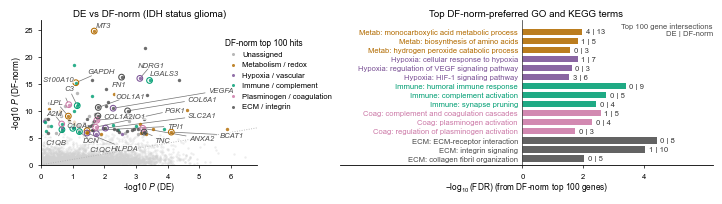

In [17]:
# Preview main row 1 without writing a PDF.
preview_subplot_panel(plot_de_df_norm_and_enrichment_row, figsize=(7.3, 1.9))

### Row 2: hypoxia and complement positive controls

In [18]:
def plot_known_gene_row(spec) -> None:
    """Draw established hypoxia and complement programs."""
    gs = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=spec, wspace=0.22)
    labels = {
        "NDRG1": "known hypoxia-response program",
        "C3": "hypoxia-driven complement / immunosuppression",
    }
    for i, gene in enumerate(FIGURE_GENES[:2]):
        draw_gene_profile_panel(
            plt.gcf(),
            gs[0, i],
            plotter=PROFILE_PLOTTER,
            gene=gene,
            narrative_label=labels[gene],
            show_legend=True,
        )

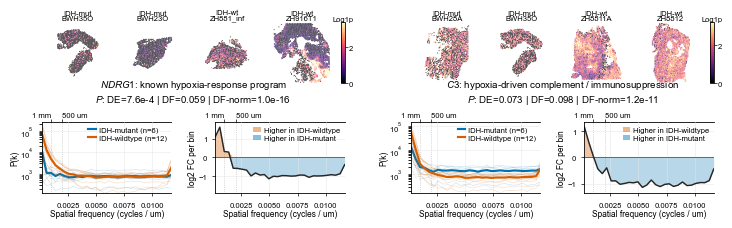

In [19]:
# Preview main row 2 without writing a PDF.
preview_subplot_panel(plot_known_gene_row, figsize=(7.3, 2.25))

### Row 3: coagulation/VTE and ECM/integrin findings

In [20]:
def plot_novel_gene_row(spec) -> None:
    """Draw coagulation/VTE and ECM/integrin findings."""
    gs = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=spec, wspace=0.22)
    labels = {
        "S100A10": "coagulation and venous thromboembolism",
        "FN1": "ECM remodeling and integrin organization",
    }
    for i, gene in enumerate(FIGURE_GENES[2:]):
        draw_gene_profile_panel(
            plt.gcf(),
            gs[0, i],
            plotter=PROFILE_PLOTTER,
            gene=gene,
            narrative_label=labels[gene],
            show_legend=True,
        )

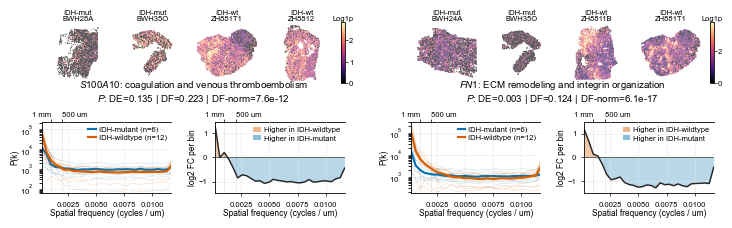

In [21]:
# Preview main row 3 without writing a PDF.
preview_subplot_panel(plot_novel_gene_row, figsize=(7.3, 2.25))

### Save as one combined main figure

In [22]:
def build_idh_status_figure() -> plt.Figure:
    """Assemble the three-row IDH-status main figure."""
    fig = plt.figure(figsize=(FIGURE_WIDTH_MM / 25.4, 210 / 25.4))
    outer = gridspec.GridSpec(
        3,
        1,
        figure=fig,
        left=0.06,
        right=0.97,
        top=0.95,
        bottom=0.05,
        height_ratios=[1.1, 1.4, 1.4],
        hspace=0.40,
    )
    plot_de_df_norm_and_enrichment_row(outer[0])
    plot_known_gene_row(outer[1])
    plot_novel_gene_row(outer[2])
    return fig

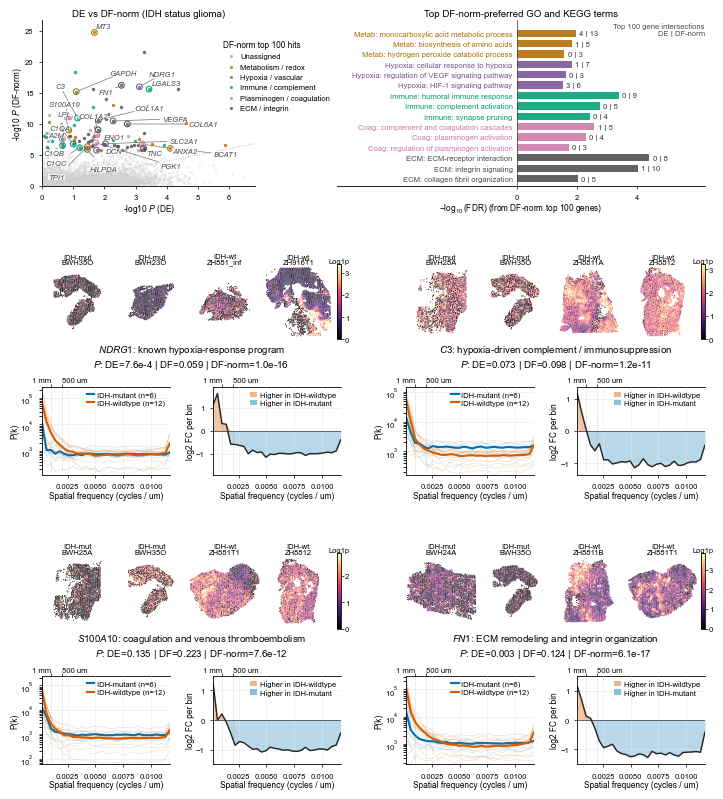

In [23]:
# Preview the combined main figure in the notebook.
fig = build_idh_status_figure()
plt.show()
plt.close(fig)

In [24]:
# Save the main figure to PDF.
fig = build_idh_status_figure()
fig.savefig(MAIN_FIGURE_PDF, bbox_inches=None, dpi=FIGURE_DPI)
plt.close(fig)
log(f"wrote {project_relative(MAIN_FIGURE_PDF)}")

[2026-09-28 00:20:53] wrote figures/glioma_idh/idh_main.pdf


## Supplement: additional gene-profile examples

### Per-program page previews

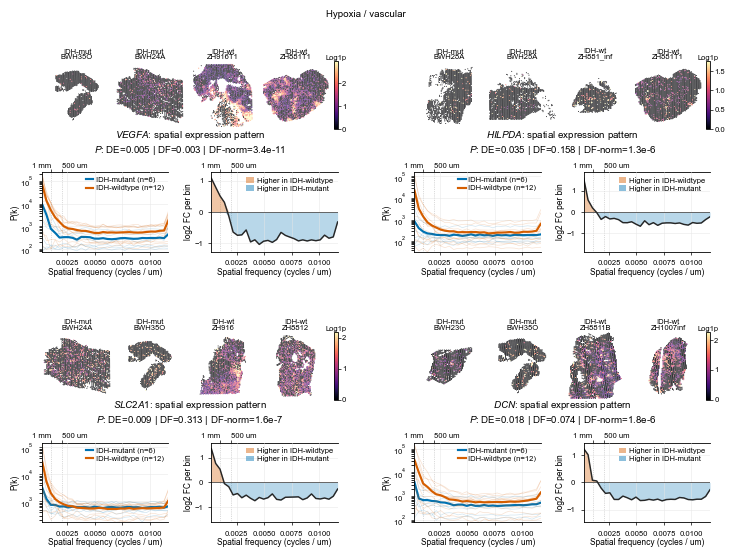

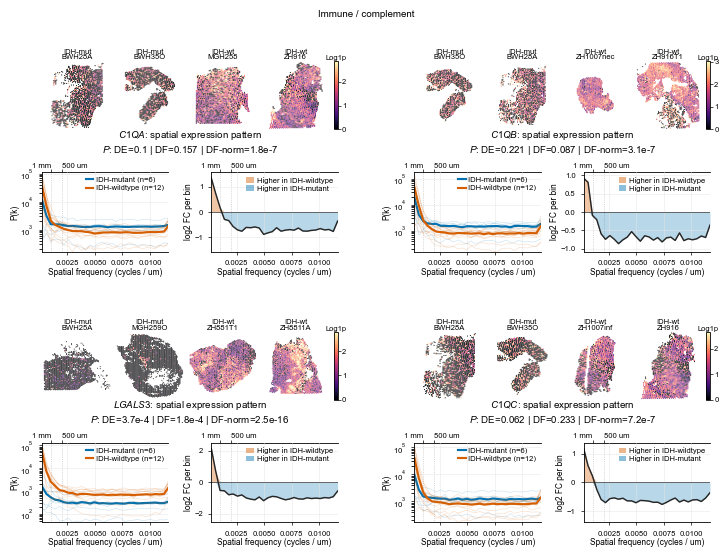

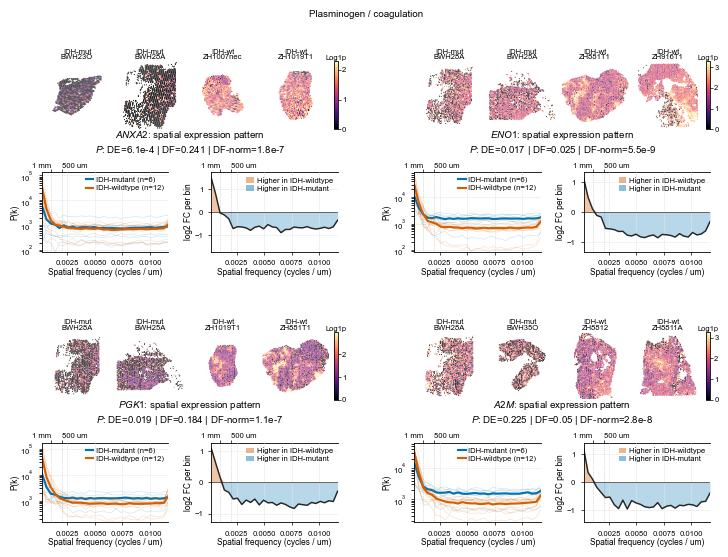

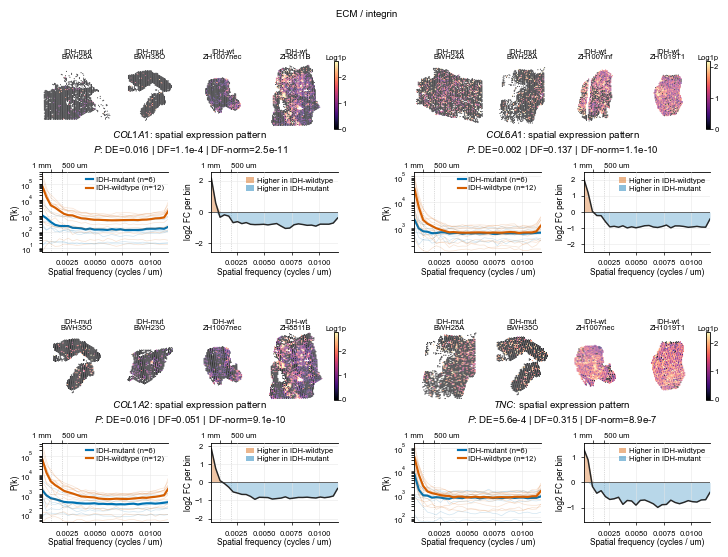

In [25]:
# Derive four discovery pages from configured examples, excluding main-figure genes.
GENE_PROFILE_PROGRAMS = tuple(
    (
        program["short_label"].lower(),
        program["label"],
        tuple(gene for gene in program["genes"] if gene not in FIGURE_GENES),
    )
    for program in META_PROGRAMS
    if program["key"] != "metabolism_redox"
)

# Preview each complete supplementary page without writing a PDF.
for _, title, genes in GENE_PROFILE_PROGRAMS:
    fig = make_gene_profile_page(genes, plotter=PROFILE_PLOTTER, sample_ids=None, page_title=title)
    plt.show()
    plt.close(fig)

### Save one single-page PDF per metaprogram

In [26]:
# Save each discovery program as its own single-page supplementary figure.
for slug, title, genes in GENE_PROFILE_PROGRAMS:
    output_pdf = FIGURE_DIR / f"idh_{slug}.pdf"
    fig = make_gene_profile_page(genes, plotter=PROFILE_PLOTTER, sample_ids=None, page_title=title)
    fig.savefig(output_pdf, bbox_inches=None, dpi=FIGURE_DPI)
    plt.close(fig)
    log(f"wrote {project_relative(output_pdf)}")

[2026-09-28 00:20:59] wrote figures/glioma_idh/idh_hypoxia.pdf
[2026-09-28 00:21:01] wrote figures/glioma_idh/idh_immune.pdf
[2026-09-28 00:21:02] wrote figures/glioma_idh/idh_coag.pdf
[2026-09-28 00:21:04] wrote figures/glioma_idh/idh_ecm.pdf
